# 06 — Product Association Mining

**Project:** RetailPulse  
**Dataset:** `data/processed/cleaned_transactions.csv`  
**Goal:** Discover products that are frequently purchased together in the same invoice and export association rules for the recommendation-engine workstream.

This notebook is deliberately separate from `03_feature_engineering.ipynb` (customer segmentation) and the completed inactivity-prediction work. It does not modify either module.

## Method
1. Validate the cleaned purchase data and construct one basket per invoice.
2. Encode invoice baskets as a sparse product-presence matrix.
3. Mine frequent itemsets with **FP-Growth** and **Apriori**.
4. Generate association rules and interpret support, confidence, and lift.
5. Export itemsets and rules to `artifacts/association/`.

**Important:** Association is not causation. A rule such as `{A} → {B}` means B appeared in invoices containing A more often than the chosen thresholds indicate; it does not prove that A causes B to be purchased.

## 1. Imports and configuration

`mlxtend` is already listed in the project's `requirements.txt`. If the import fails in a fresh environment, install the project requirements with `pip install -r requirements.txt`.

The thresholds below are explicit experiment settings, not claimed optimal values. Start with 1% invoice support and inspect the resulting itemsets/rules before adjusting.

In [13]:
import json

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_ROOT = Path.cwd()
# Supports running from either the project root or the notebooks/ directory.
if not (PROJECT_ROOT / "data" / "processed").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "cleaned_transactions.csv"
OUTPUT_DIR = PROJECT_ROOT / "artifacts" / "association"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MIN_SUPPORT = 0.01
MIN_CONFIDENCE = 0.20
MIN_LIFT = 1.0
MAX_ITEMSET_LENGTH = 3

print("Project root:", PROJECT_ROOT.resolve())
print("Input exists:", DATA_PATH.exists())
print("Output directory:", OUTPUT_DIR.resolve())

Project root: C:\Users\Mehak\OneDrive\MEHAK\Desktop\RetailPulse
Input exists: True
Output directory: C:\Users\Mehak\OneDrive\MEHAK\Desktop\RetailPulse\artifacts\association


## 2. Load and validate transactions

The project's cleaned file is already restricted to positive-price, positive-quantity purchase rows and excludes cancellation/return records. We still validate the columns and apply defensive row-level checks here.

Customer ID is intentionally **not** required: baskets are invoice-level, so anonymous-customer invoices can contribute valid product co-occurrence information.

In [2]:
required_columns = {"Invoice", "StockCode", "Description", "Quantity", "Price"}
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Could not find {DATA_PATH}. Run this notebook from the project or notebooks directory.")

transactions = pd.read_csv(DATA_PATH, low_memory=False)
missing_columns = required_columns - set(transactions.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

input_rows = len(transactions)
transactions["Invoice"] = transactions["Invoice"].astype("string").str.strip()
transactions["StockCode"] = transactions["StockCode"].astype("string").str.strip()
transactions["Description"] = transactions["Description"].astype("string").str.strip()
transactions["Quantity"] = pd.to_numeric(transactions["Quantity"], errors="coerce")
transactions["Price"] = pd.to_numeric(transactions["Price"], errors="coerce")

# Keep valid purchase lines only; do not require Customer ID.
valid_mask = (
    transactions["Invoice"].notna()
    & transactions["StockCode"].notna()
    & transactions["Description"].notna()
    & transactions["Quantity"].gt(0)
    & transactions["Price"].gt(0)
    & ~transactions["Invoice"].str.upper().str.startswith("C", na=False)
)
purchase_lines = transactions.loc[valid_mask].copy()
purchase_lines["Description"] = purchase_lines["Description"].str.upper().str.strip()

print(f"Input rows: {input_rows:,}")
print(f"Valid purchase lines: {len(purchase_lines):,}")
print(f"Excluded by notebook validation: {input_rows - len(purchase_lines):,}")
print(f"Unique invoices: {purchase_lines['Invoice'].nunique():,}")
print(f"Unique products (StockCode): {purchase_lines['StockCode'].nunique():,}")
print(f"Rows with missing Customer ID retained: {purchase_lines['Customer ID'].isna().sum():,}")

Input rows: 1,007,913
Valid purchase lines: 1,007,913
Excluded by notebook validation: 0
Unique invoices: 40,077
Unique products (StockCode): 4,916
Rows with missing Customer ID retained: 228,488


In [3]:
display(purchase_lines[["Invoice", "StockCode", "Description", "Quantity", "Price"]].head())
display(purchase_lines[["Quantity", "Price"]].describe())

,Invoice,StockCode,Description,Quantity,Price
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,6.95
1,489434,79323P,PINK CHERRY LIGHTS,12,6.75
2,489434,79323W,WHITE CHERRY LIGHTS,12,6.75
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2.10
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,1.25


,Quantity,Price
count,1.007913e+06,1.007913e+06
mean,1.111718e+01,4.074252e+00
std,1.284700e+02,5.043045e+01
min,1.000000e+00,1.000000e-03
25%,1.000000e+00,1.250000e+00
50%,4.000000e+00,2.100000e+00
75%,1.200000e+01,4.130000e+00
max,8.099500e+04,2.511109e+04


## 3. Build invoice-level product baskets

A basket represents the **presence** of a product in an invoice, not the number of units purchased. If an invoice contains repeated lines for the same StockCode, that product appears only once in that basket.

`StockCode` is used as the product key because descriptions can vary in formatting. A representative description is retained for readable rule output.

In [4]:
# One product occurrence per invoice.
invoice_products = (
    purchase_lines[["Invoice", "StockCode"]]
    .drop_duplicates()
    .sort_values(["Invoice", "StockCode"])
)

baskets = (
    invoice_products.groupby("Invoice")["StockCode"]
    .apply(list)
    .tolist()
)

product_descriptions = (
    purchase_lines.dropna(subset=["StockCode", "Description"])
    .drop_duplicates("StockCode")
    .set_index("StockCode")["Description"]
    .to_dict()
)

basket_sizes = pd.Series([len(basket) for basket in baskets], name="products_per_invoice")
print(f"Number of baskets: {len(baskets):,}")
print(f"Unique products in baskets: {len(product_descriptions):,}")
display(basket_sizes.describe(percentiles=[.5, .9, .95, .99]).to_frame())

Number of baskets: 40,077
Unique products in baskets: 4,916


,products_per_invoice
count,40077.000000
mean,24.865833
std,42.179048
min,1.000000
50%,15.000000
90%,50.000000
95%,72.000000
99%,196.000000
max,1110.000000


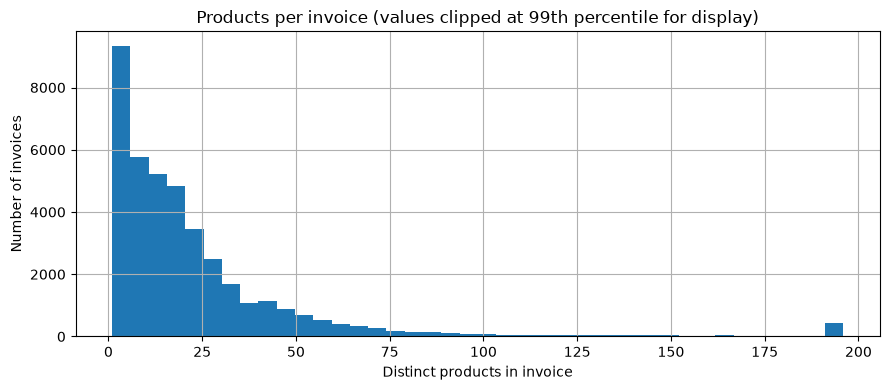

In [12]:
plt.figure(figsize=(9, 4))
basket_sizes.clip(upper=basket_sizes.quantile(0.99)).hist(bins=40)
plt.title("Products per invoice (values clipped at 99th percentile for display)")
plt.xlabel("Distinct products in invoice")
plt.ylabel("Number of invoices")
plt.tight_layout()
plt.show()

## 4. Sparse basket encoding

The invoice × product matrix is stored sparsely to avoid allocating a dense matrix for thousands of products and tens of thousands of invoices.

In [5]:
encoder = TransactionEncoder()
encoded_array = encoder.fit(baskets).transform(baskets, sparse=True)
basket_matrix = pd.DataFrame.sparse.from_spmatrix(
    encoded_array,
    columns=encoder.columns_
)

print("Basket matrix shape:", basket_matrix.shape)
print("Storage type:", type(basket_matrix.dtypes.iloc[0]).__name__)
print("Share of present invoice-product pairs:", round(
    len(invoice_products) / (basket_matrix.shape[0] * basket_matrix.shape[1]), 6
))

Basket matrix shape: (40077, 4916)
Storage type: SparseDtype
Share of present invoice-product pairs: 0.005058


## 5. Frequent itemsets — FP-Growth

FP-Growth mines frequent product combinations without candidate generation. The maximum itemset length is capped at three to keep the initial analysis focused on pairs and small combinations.

In [6]:
frequent_itemsets_fp = fpgrowth(
    basket_matrix,
    min_support=MIN_SUPPORT,
    use_colnames=True,
    max_len=MAX_ITEMSET_LENGTH
).sort_values(["support", "itemsets"], ascending=[False, True]).reset_index(drop=True)

print(f"FP-Growth itemsets found: {len(frequent_itemsets_fp):,}")
display(frequent_itemsets_fp.head(20))

FP-Growth itemsets found: 1,332


,support,itemsets
0,0.133867,(85123A)
1,0.099533,(85099B)
2,0.097762,(22423)
3,0.077800,(21212)
4,0.076253,(20725)
5,0.070040,(84879)
6,0.066722,(47566)
7,0.060758,(21232)
8,0.059835,(22383)
9,0.058662,(20727)


## 6. Frequent itemsets — Apriori

Apriori is run with the same support and itemset-length settings to provide a second mining implementation for comparison. `low_memory=True` reduces candidate-generation memory pressure, although Apriori can still be slower than FP-Growth on this dataset.

In [7]:
frequent_itemsets_ap = apriori(
    basket_matrix,
    min_support=MIN_SUPPORT,
    use_colnames=True,
    max_len=MAX_ITEMSET_LENGTH,
    low_memory=True
).sort_values(["support", "itemsets"], ascending=[False, True]).reset_index(drop=True)

print(f"Apriori itemsets found: {len(frequent_itemsets_ap):,}")
print("Same itemset count:", len(frequent_itemsets_fp) == len(frequent_itemsets_ap))
display(frequent_itemsets_ap.head(20))

Apriori itemsets found: 1,332
Same itemset count: True


,support,itemsets
0,0.133867,(85123A)
1,0.099533,(85099B)
2,0.097762,(22423)
3,0.077800,(21212)
4,0.076253,(20725)
5,0.070040,(84879)
6,0.066722,(47566)
7,0.060758,(21232)
8,0.059835,(22383)
9,0.058662,(20727)


## 7. Generate association rules

For each rule:
- **Support:** fraction of all invoices containing both antecedent and consequent.
- **Confidence:** fraction of invoices containing the antecedent that also contain the consequent.
- **Lift:** confidence divided by the consequent's overall support. Lift above 1 indicates a positive association relative to the baseline frequency of the consequent.

We generate rules from FP-Growth itemsets and then apply transparent minimum-confidence and lift filters.

In [8]:
if frequent_itemsets_fp.empty:
    raise ValueError(
        "No frequent itemsets were found. Lower MIN_SUPPORT gradually (for example, 0.005) "
        "and rerun the mining cells."
    )

rules = association_rules(
    frequent_itemsets_fp,
    metric="confidence",
    min_threshold=MIN_CONFIDENCE
)

if not rules.empty:
    rules = rules.loc[rules["lift"] >= MIN_LIFT].copy()
    rules = rules.sort_values(
        ["lift", "confidence", "support"],
        ascending=[False, False, False]
    ).reset_index(drop=True)

print(f"Rules after confidence >= {MIN_CONFIDENCE:.2f} and lift >= {MIN_LIFT:.2f}: {len(rules):,}")
display(rules.head(20))

Rules after confidence >= 0.20 and lift >= 1.00: 1,344


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,"(22748, 22745)",(22746),0.013898,0.014073,0.010205,0.734291,52.177614,1.0,0.010010,3.710550,0.994659,0.574438,0.730498,0.729734
1,(22746),"(22748, 22745)",0.014073,0.013898,0.010205,0.725177,52.177614,1.0,0.010010,3.588138,0.994835,0.574438,0.721304,0.729734
2,"(22748, 22746)",(22745),0.011827,0.017541,0.010205,0.862869,49.190909,1.0,0.009998,7.164392,0.991397,0.532552,0.860421,0.722331
3,(22745),"(22748, 22746)",0.017541,0.011827,0.010205,0.581792,49.190909,1.0,0.009998,2.362876,0.997163,0.532552,0.576787,0.722331
4,"(22745, 22746)",(22748),0.011503,0.018514,0.010205,0.887202,47.919655,1.0,0.009992,8.701248,0.990526,0.515113,0.885074,0.719207
5,(22748),"(22745, 22746)",0.018514,0.011503,0.010205,0.551213,47.919655,1.0,0.009992,2.202597,0.997602,0.515113,0.545991,0.719207
6,(22746),(22745),0.014073,0.017541,0.011503,0.817376,46.597402,1.0,0.011256,5.379677,0.992507,0.571960,0.814115,0.736568
7,(22745),(22746),0.017541,0.014073,0.011503,0.655761,46.597402,1.0,0.011256,2.864077,0.996011,0.571960,0.650847,0.736568
8,(22748),(22746),0.018514,0.014073,0.011827,0.638814,45.393173,1.0,0.011567,2.729694,0.996418,0.569712,0.633659,0.739620
9,(22746),(22748),0.014073,0.018514,0.011827,0.840426,45.393173,1.0,0.011567,6.150643,0.991930,0.569712,0.837415,0.739620


## 8. Make rules readable

The mining algorithm uses StockCode values as stable product identifiers. The following view adds representative descriptions while preserving the underlying codes.

In [9]:
def describe_items(itemset):
    codes = sorted(str(code) for code in itemset)
    return " + ".join(
        f"{code} ({product_descriptions.get(code, 'Description unavailable')})"
        for code in codes
    )

if rules.empty:
    readable_rules = pd.DataFrame(columns=[
        "antecedents", "consequents", "antecedent_codes", "consequent_codes",
        "support", "confidence", "lift", "leverage", "conviction"
    ])
else:
    readable_rules = rules.copy()
    readable_rules["antecedent_codes"] = readable_rules["antecedents"].apply(
        lambda x: " | ".join(sorted(map(str, x)))
    )
    readable_rules["consequent_codes"] = readable_rules["consequents"].apply(
        lambda x: " | ".join(sorted(map(str, x)))
    )
    readable_rules["antecedents"] = readable_rules["antecedents"].apply(describe_items)
    readable_rules["consequents"] = readable_rules["consequents"].apply(describe_items)

display(readable_rules[[
    "antecedents", "consequents", "support", "confidence", "lift"
]].head(25))

,antecedents,consequents,support,confidence,lift
0,22745 (POPPY'S PLAYHOUSE BEDROOM) + 22748 (POP...,22746 (POPPY'S PLAYHOUSE LIVINGROOM),0.010205,0.734291,52.177614
1,22746 (POPPY'S PLAYHOUSE LIVINGROOM),22745 (POPPY'S PLAYHOUSE BEDROOM) + 22748 (POP...,0.010205,0.725177,52.177614
2,22746 (POPPY'S PLAYHOUSE LIVINGROOM) + 22748 (...,22745 (POPPY'S PLAYHOUSE BEDROOM),0.010205,0.862869,49.190909
3,22745 (POPPY'S PLAYHOUSE BEDROOM),22746 (POPPY'S PLAYHOUSE LIVINGROOM) + 22748 (...,0.010205,0.581792,49.190909
4,22745 (POPPY'S PLAYHOUSE BEDROOM) + 22746 (POP...,22748 (POPPY'S PLAYHOUSE KITCHEN),0.010205,0.887202,47.919655
5,22748 (POPPY'S PLAYHOUSE KITCHEN),22745 (POPPY'S PLAYHOUSE BEDROOM) + 22746 (POP...,0.010205,0.551213,47.919655
6,22746 (POPPY'S PLAYHOUSE LIVINGROOM),22745 (POPPY'S PLAYHOUSE BEDROOM),0.011503,0.817376,46.597402
7,22745 (POPPY'S PLAYHOUSE BEDROOM),22746 (POPPY'S PLAYHOUSE LIVINGROOM),0.011503,0.655761,46.597402
8,22748 (POPPY'S PLAYHOUSE KITCHEN),22746 (POPPY'S PLAYHOUSE LIVINGROOM),0.011827,0.638814,45.393173
9,22746 (POPPY'S PLAYHOUSE LIVINGROOM),22748 (POPPY'S PLAYHOUSE KITCHEN),0.011827,0.840426,45.393173


## 9. Inspect the strongest rules

These plots are descriptive views of the mined rules. They do not represent predictive accuracy or causal effects.

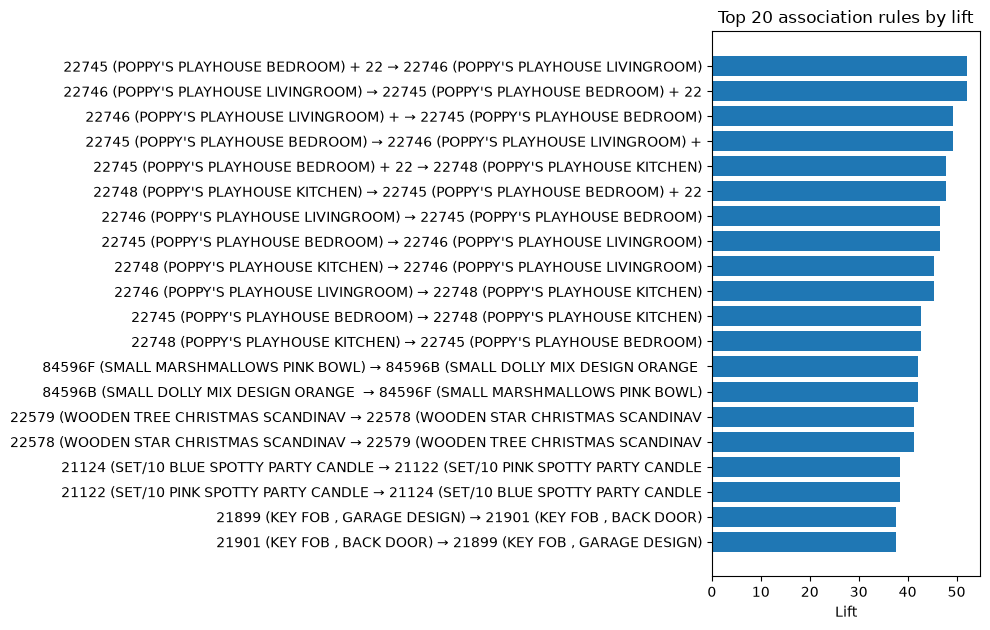

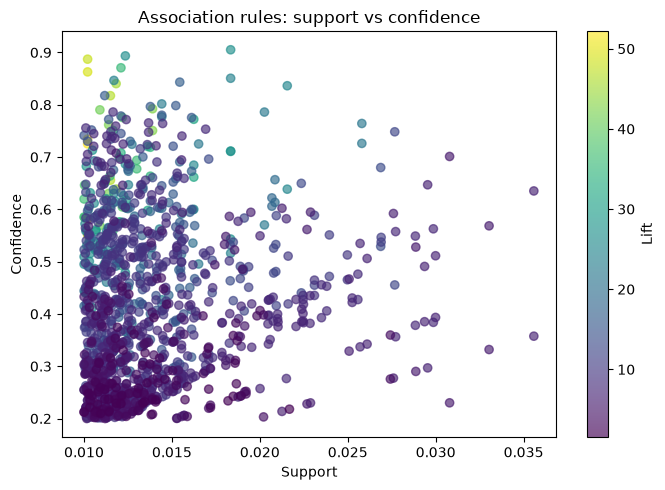

In [10]:
if not rules.empty:
    plot_rules = rules.head(20).copy()
    plot_rules["rule_label"] = plot_rules.apply(
        lambda row: f"{describe_items(row['antecedents'])[:38]} → {describe_items(row['consequents'])[:38]}",
        axis=1
    )
    plt.figure(figsize=(10, max(5, len(plot_rules) * 0.32)))
    plt.barh(plot_rules["rule_label"][::-1], plot_rules["lift"][::-1])
    plt.xlabel("Lift")
    plt.title("Top 20 association rules by lift")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7, 5))
    plt.scatter(rules["support"], rules["confidence"], c=rules["lift"], alpha=0.65)
    plt.xlabel("Support")
    plt.ylabel("Confidence")
    plt.title("Association rules: support vs confidence")
    plt.colorbar(label="Lift")
    plt.tight_layout()
    plt.show()
else:
    print("No rules satisfy the current confidence and lift thresholds.")

## 10. Export artifacts for the recommendation engine

The exports retain machine-readable StockCode sets as pipe-separated values, along with readable descriptions and rule metrics. The recommendation engine can use `antecedent_codes` to look up matching consequents.

Files:
- `frequent_itemsets_fp_growth.csv`
- `frequent_itemsets_apriori.csv`
- `association_rules.csv` (filtered rules, readable plus codes)
- `association_run_summary.json`

In [14]:
def itemset_to_codes(itemset):
    return "|".join(sorted(map(str, itemset)))

fp_export = frequent_itemsets_fp.copy()
fp_export["itemset_codes"] = fp_export["itemsets"].apply(itemset_to_codes)
fp_export["itemset_descriptions"] = fp_export["itemsets"].apply(describe_items)
fp_export["itemset_length"] = fp_export["itemsets"].apply(len)
fp_export = fp_export.drop(columns=["itemsets"])

ap_export = frequent_itemsets_ap.copy()
ap_export["itemset_codes"] = ap_export["itemsets"].apply(itemset_to_codes)
ap_export["itemset_descriptions"] = ap_export["itemsets"].apply(describe_items)
ap_export["itemset_length"] = ap_export["itemsets"].apply(len)
ap_export = ap_export.drop(columns=["itemsets"])

rule_export = readable_rules.copy()
if not rule_export.empty:
    rule_export = rule_export.drop(columns=["antecedents", "consequents"])

fp_path = OUTPUT_DIR / "frequent_itemsets_fp_growth.csv"
ap_path = OUTPUT_DIR / "frequent_itemsets_apriori.csv"
rules_path = OUTPUT_DIR / "association_rules.csv"

fp_export.to_csv(fp_path, index=False)
ap_export.to_csv(ap_path, index=False)
rule_export.to_csv(rules_path, index=False)

summary = {
    "input_file": str(DATA_PATH.relative_to(PROJECT_ROOT)),
    "valid_purchase_lines": int(len(purchase_lines)),
    "invoice_baskets": int(len(baskets)),
    "unique_products": int(basket_matrix.shape[1]),
    "min_support": MIN_SUPPORT,
    "min_confidence": MIN_CONFIDENCE,
    "min_lift": MIN_LIFT,
    "max_itemset_length": MAX_ITEMSET_LENGTH,
    "fp_growth_itemsets": int(len(frequent_itemsets_fp)),
    "apriori_itemsets": int(len(frequent_itemsets_ap)),
    "filtered_association_rules": int(len(rule_export))
}
summary_path = OUTPUT_DIR / "association_run_summary.json"
summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")

print("Saved:")
for path in [fp_path, ap_path, rules_path, summary_path]:
    print("-", path.relative_to(PROJECT_ROOT))

Saved:
- artifacts\association\frequent_itemsets_fp_growth.csv
- artifacts\association\frequent_itemsets_apriori.csv
- artifacts\association\association_rules.csv
- artifacts\association\association_run_summary.json


## 11. Interpretation and handoff

When reviewing the exported rules, prioritize:
1. Adequate support — rules based on very few invoices may be unstable.
2. Useful confidence — how often the consequent appears when the antecedent is present.
3. Lift above 1 — whether the consequent is more common with the antecedent than overall.
4. Business relevance — product descriptions and combinations should make sense to a retailer.

The next recommendation-engine module can consume `artifacts/association/association_rules.csv`. A simple rule-based recommendation can match a customer's/cart's currently selected StockCode values against `antecedent_codes` and rank candidate consequents using confidence, lift, and support.

**Limitations:** This is invoice-level co-occurrence analysis on one retailer's historical transactions. It does not account for product availability, price changes, seasonality, customer intent, or causal effects. The current support/confidence thresholds are starting settings and should be revisited after inspecting the actual number and quality of rules.